# Gráficos de la preparación de los datos

Práctica Visualización de datos, parte 1. Este notebook acompaña al apartado 6 del documento (*Preparación de los datos y proceso de trabajo*) y muestra los gráficos con los que revisé el conjunto antes de diseñar la visualización:

1. Completitud por año y el filtro del 30 % en los años finales.
2. Cobertura de cada variable.
3. Niveles de renta antes y después de homogeneizar las etiquetas.
4. Valores extremos con diagramas de caja e histogramas (escolarización bruta y CO₂ por habitante).
5. Primera comprobación de las hipótesis del apartado 5 (preguntas y objetivos), con las cifras que cito en el documento.

Necesita `dataset_final.csv` e `informe_cobertura.csv` en la misma carpeta, que genera `construir_dataset.py`. Repositorio: https://github.com/ikss-DSi/PEC_PARTES

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "font.size": 10,
})
AZUL, NARANJA, GRIS = "#2a6fb0", "#e07b39", "#9aa5b1"

df = pd.read_csv("dataset_final.csv")
cobertura = pd.read_csv("informe_cobertura.csv", index_col=0)
RENTA = "Income Classification (World Bank Definition)"
print(f"{len(df):,}".replace(",", "."), f"filas, {df.shape[1]} columnas, {df.iso3.nunique()} países, {df.anio.min()}-{df.anio.max()}")

4.325 filas, 75 columnas, 173 países, 2000-2024


## 1. Completitud por año y filtro del 30 %

El Banco Mundial tarda uno o dos años en publicar muchas series. Por eso, si pido datos hasta 2025, la API devuelve los últimos años casi vacíos. Si los dejara, en un gráfico de líneas parecería que los indicadores caen o desaparecen al final. Sería un efecto del calendario de publicación, no de los datos.

Para evitarlo, el script calcula qué parte de las celdas tiene valor en cada año y se queda hasta el último año que supera el 30 %. Solo cuentan las variables que el script descarga y actualiza. Las que son fijas por país, como el continente, la región o el nivel de renta, siempre tienen valor y harían que un año vacío pareciera completo.

El 30 % es un criterio práctico mío, no viene del material del curso. Lo puse bajo a propósito: quiero quitar solo los años que están prácticamente vacíos y quedarme con los que tienen datos útiles aunque tengan huecos. El precio es que entran años con bastantes huecos, así que en los gráficos de esos años diré cuántos países tienen dato, para que una media no cambie solo porque faltan países.

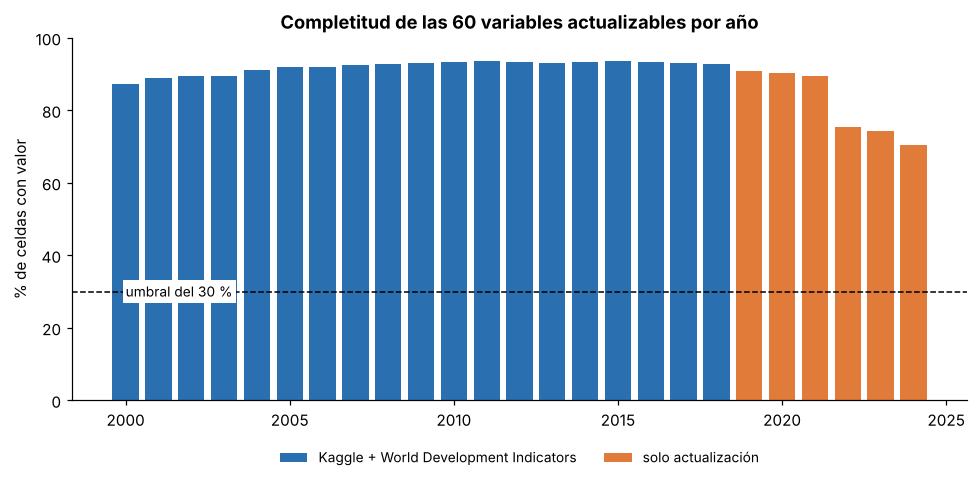

anio
2018    92.8
2019    90.9
2020    90.3
2021    89.4
2022    75.5
2023    74.3
2024    70.4


In [2]:
from matplotlib.patches import Patch

ids = ["iso3", "pais", "anio", "periodo"]
actualizables = [c for c in df.columns if c not in ids and df.loc[df.anio >= 2019, c].notna().any()]
llenado = df[actualizables].notna().groupby(df.anio).mean() * 100
media_anual = llenado.mean(axis=1)

fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [AZUL if a <= 2018 else NARANJA for a in media_anual.index]
ax.bar(media_anual.index, media_anual.values, color=colores)
ax.axhline(30, color="black", lw=1, ls="--")
ax.text(2000, 30, "umbral del 30 %", fontsize=9, va="center",
        bbox=dict(facecolor="white", edgecolor="none", pad=2), zorder=3)
ax.set_ylim(0, 100)
ax.set_ylabel("% de celdas con valor")
ax.set_title(f"Completitud de las {len(actualizables)} variables actualizables por año")

leyenda = [Patch(facecolor=AZUL, label="Kaggle + World Development Indicators"),
           Patch(facecolor=NARANJA, label="solo actualización")]
ax.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.1),
          ncol=2, frameon=False, fontsize=9)

plt.tight_layout(); plt.show()
print(media_anual.round(1).tail(7).to_string())


La completitud baja en **2019-2021 y cae a cerca del 70-75 % en 2022-2024**, porque muchas series tardan **uno o dos años** en publicarse o se dejaron de actualizar. Aun así, 2024 sigue muy por encima del umbral. Por eso el conjunto termina en 2024 y no en 2025 para años "completos".

## 2. Cobertura de cada variable

Porcentaje de filas país-año con valor en cada variable, según `informe_cobertura.csv`. En naranja, las series que terminan antes de 2024 (por ejemplo el índice *Women, Business and the Law*, que en la API llega hasta 2018).

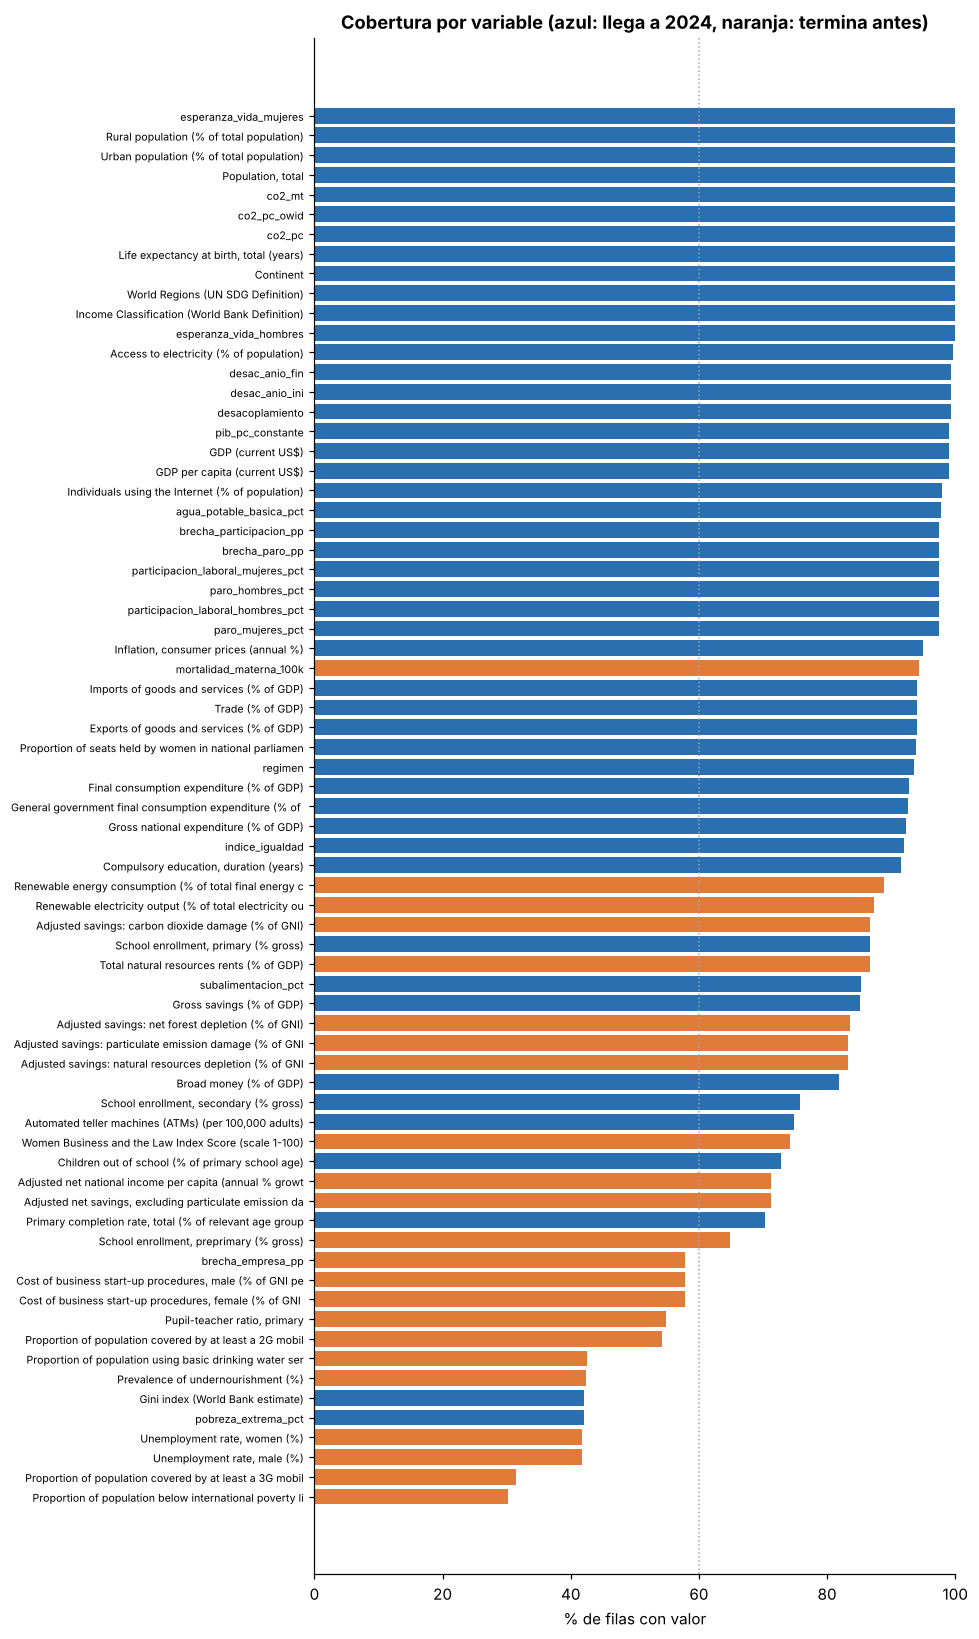

Variables con menos del 60 % de valores: 13


In [3]:
cob = cobertura.drop(index=[c for c in ids if c in cobertura.index]).copy()
cob["corto"] = [n.split(" - ")[0][:55] for n in cob.index]
cob = cob.sort_values("pct_valores")
fig, ax = plt.subplots(figsize=(9, 15))
col = [NARANJA if u < 2024 else AZUL for u in cob.ultimo_anio]
ax.barh(cob.corto, cob.pct_valores, color=col)
ax.axvline(60, color=GRIS, lw=1, ls=":")
ax.set_xlabel("% de filas con valor"); ax.set_xlim(0, 100)
ax.tick_params(axis="y", labelsize=7)
ax.set_title("Cobertura por variable (azul: llega a 2024, naranja: termina antes)")
plt.tight_layout(); plt.show()
print("Variables con menos del 60 % de valores:", (cob.pct_valores < 60).sum())

## 3. Niveles de renta antes y después de homogeneizar

La API del Banco Mundial escribe *Upper middle income* y *Lower middle income*, y el Kaggle *Upper-middle income* y *Lower-middle income*. Al unir las dos fuentes salían 6 niveles de renta en vez de 4.
Reconstruyo la muestra original y la comparo para evitar dudas sobre el uso de la nomenclatura de las fuentes que utilicé.

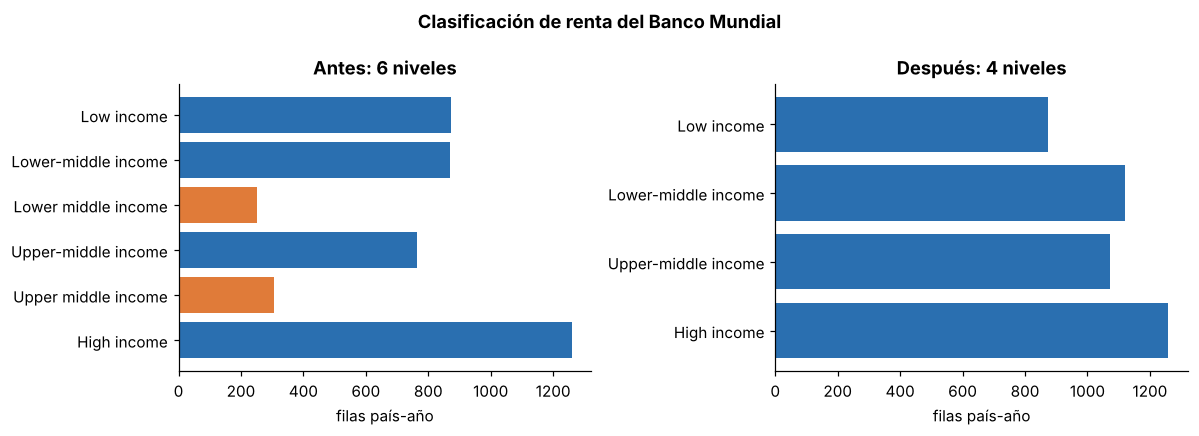

Niveles antes: 6 | niveles después: 4


In [4]:
antes = df[RENTA].copy()
desde_api = df.anio >= 2019
antes[desde_api] = antes[desde_api].str.replace(r"^(Upper|Lower)-middle", r"\1 middle", regex=True)
despues = antes.str.replace(r"^(Upper|Lower) middle", r"\1-middle", regex=True)

orden = ["Low income", "Lower-middle income", "Lower middle income",
         "Upper-middle income", "Upper middle income", "High income"]
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharex=True)
for ax, serie, titulo in [(axs[0], antes, "Antes: 6 niveles"), (axs[1], despues, "Después: 4 niveles")]:
    n = serie.value_counts().reindex(orden).dropna()
    col = [NARANJA if " middle" in e else AZUL for e in n.index]
    ax.barh(n.index, n.values, color=col)
    ax.invert_yaxis(); ax.set_title(titulo); ax.set_xlabel("filas país-año")
plt.suptitle("Clasificación de renta del Banco Mundial", fontweight="bold")
plt.tight_layout(); plt.show()
print("Niveles antes:", antes.nunique(), "| niveles después:", despues.nunique())

## 4. Valores extremos

### 4.1 Escolarización bruta

La escolarización bruta divide a todos los alumnos matriculados entre la población en edad oficial de ese nivel. Como cuenta también a quienes repiten o empiezan tarde, puede pasar del 100 %. Esos valores son correctos, así que no los borré.

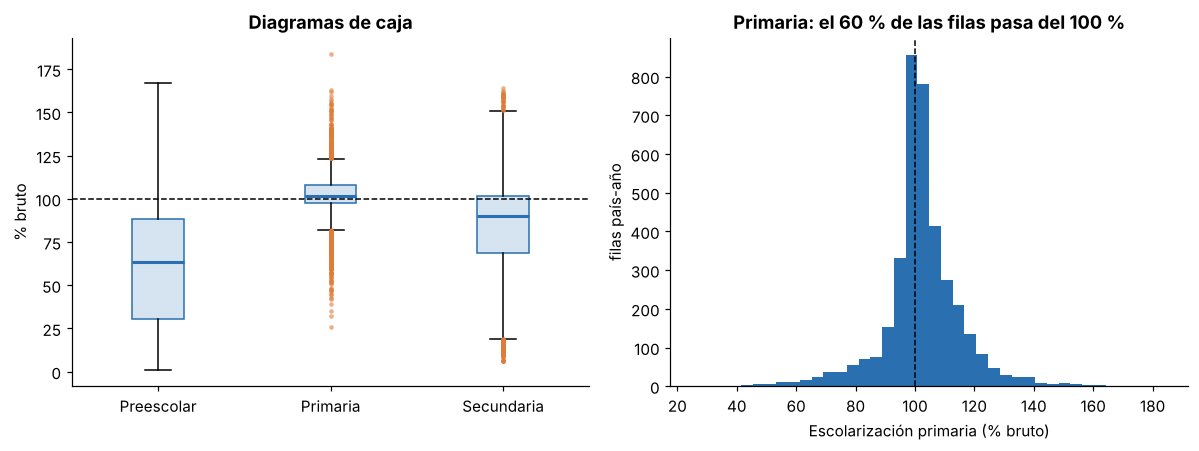

,país,año,primaria % bruto
1766,Haiti,2016,184.0
3547,Sierra Leone,2022,163.2
3549,Sierra Leone,2024,162.1
3548,Sierra Leone,2023,159.4
3546,Sierra Leone,2021,157.7


In [5]:
esc = {
    "Preescolar": "School enrollment, preprimary (% gross) - SE.PRE.ENRR",
    "Primaria": "School enrollment, primary (% gross) - SE.PRM.ENRR",
    "Secundaria": "School enrollment, secondary (% gross) - SE.SEC.ENRR",
}
datos = [df[c].dropna() for c in esc.values()]
fig, axs = plt.subplots(1, 2, figsize=(11, 4.2))
axs[0].boxplot(datos, tick_labels=list(esc), patch_artist=True,
               boxprops=dict(facecolor="#d6e4f2", color=AZUL), medianprops=dict(color=AZUL, lw=2),
               flierprops=dict(marker="o", markersize=3, markerfacecolor=NARANJA, markeredgecolor="none", alpha=.6))
axs[0].axhline(100, color="black", lw=1, ls="--"); axs[0].set_ylabel("% bruto")
axs[0].set_title("Diagramas de caja")
prim = df[esc["Primaria"]].dropna()
axs[1].hist(prim, bins=40, color=AZUL)
axs[1].axvline(100, color="black", lw=1, ls="--")
axs[1].set_xlabel("Escolarización primaria (% bruto)"); axs[1].set_ylabel("filas país-año")
axs[1].set_title(f"Primaria: el {(prim > 100).mean()*100:.0f} % de las filas pasa del 100 %")
plt.tight_layout(); plt.show()

top = (df.loc[df[esc["Primaria"]].notna(), ["pais", "anio", esc["Primaria"]]]
         .sort_values(esc["Primaria"], ascending=False).head(5))
top.columns = ["país", "año", "primaria % bruto"]; top.round(1)

### 4.2 CO₂ por habitante según nivel de renta (2022)

El CO₂ por habitante tiene una cola larga: unos pocos países petroleros o muy pequeños emiten mucho más que el resto de su grupo. Son datos reales, así que los mantengo, pero me obligan a usar una escala que no aplaste al resto de países, por ejemplo logarítmica.

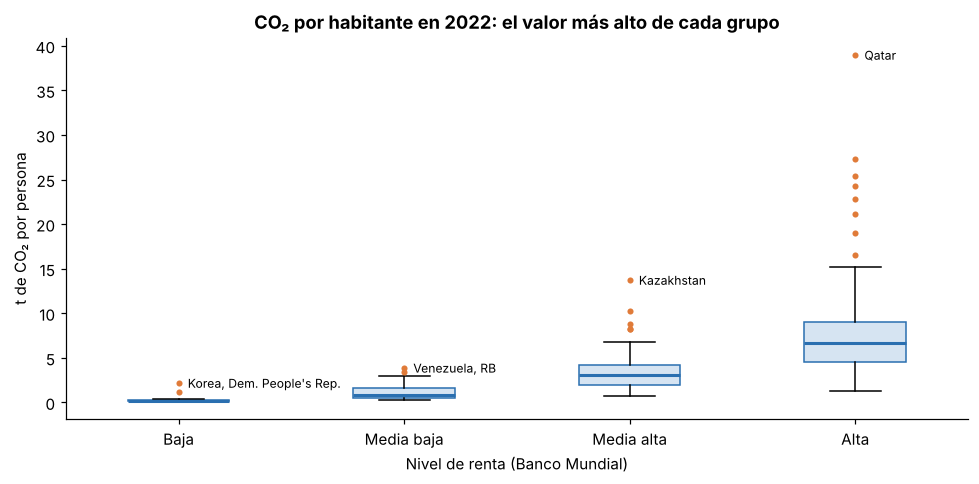

In [6]:
d = df[(df.anio == 2022) & df.co2_pc.notna() & df[RENTA].notna()]
niveles = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]
grupos = [d.loc[d[RENTA] == n, "co2_pc"] for n in niveles]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.boxplot(grupos, tick_labels=["Baja", "Media baja", "Media alta", "Alta"], patch_artist=True,
           boxprops=dict(facecolor="#d6e4f2", color=AZUL), medianprops=dict(color=AZUL, lw=2),
           flierprops=dict(marker="o", markersize=4, markerfacecolor=NARANJA, markeredgecolor="none"))
for i, n in enumerate(niveles, start=1):
    g = d[d[RENTA] == n].nlargest(1, "co2_pc")
    for _, r in g.iterrows():
        ax.annotate(r.pais, (i, r.co2_pc), xytext=(6, 0), textcoords="offset points", fontsize=8, va="center")
ax.set_ylabel("t de CO₂ por persona"); ax.set_xlabel("Nivel de renta (Banco Mundial)")
ax.set_title("CO₂ por habitante en 2022: el valor más alto de cada grupo")
plt.tight_layout(); plt.show()

## 5. Qué me llevo de esta revisión

- El filtro del 30 % deja el conjunto en 2000-2024, con la caída de completitud a partir de 2022 a la vista.
- Las variables con cobertura baja (Gini, pobreza, coste de crear empresa) las usaré con cuidado y siempre diciendo cuántos países tienen dato.
- Con la renta homogeneizada ya puedo usarla como dimensión con 4 niveles.
- Los valores extremos que vi son legítimos, así que no los quito: los trato con la escala y con anotaciones en la visualización.

## 6. Primera comprobación de las hipótesis (apartado 5)

En el apartado 5 del documento cada pregunta tiene una hipótesis y una primera comprobación con los datos. Aquí calculo esas cifras, para que se puedan revisar. Son una exploración inicial, no conclusiones: en la parte 2 las mostraré con visualizaciones y con el contexto de los huecos de datos.

In [7]:
import numpy as np

ESC = "Proportion of seats held by women in national parliaments (%) - SG.GEN.PARL.ZS"
REN = "Renewable energy consumption (% of total final energy consumption) - EG.FEC.RNEW.ZS"
ELEC = "Access to electricity (% of population) - EG.ELC.ACCS.ZS"
POB = "Population, total - SP.POP.TOTL"
REG = "World Regions (UN SDG Definition)"
NIVELES = ["Low income", "Lower-middle income", "Upper-middle income", "High income"]
ETIQ = {"Low income": "Baja", "Lower-middle income": "Media baja",
        "Upper-middle income": "Media alta", "High income": "Alta"}

### 6.1 Tendencia: escaños de mujeres por región (pregunta 1)

*Hipótesis:* las regiones que partían más abajo suben más rápido, así que las diferencias se acortan. Calculo la media simple de países de cada región en 2000 y en 2024, y la distancia entre la región más alta y la más baja.

anio                               2000  2024  cambio (p. p.)
World Regions (UN SDG Definition)                            
Central and Southern Asia           7.8  17.4             9.6
Oceania                            11.2  18.0             6.8
Northern Africa and Western Asia    4.8  19.6            14.8
Eastern and South-Eastern Asia     12.2  21.9             9.7
Sub-Saharan Africa                 10.7  25.7            15.0
Latin America and Caribbean        12.3  31.5            19.2
Europe and Northern America        18.9  32.6            13.7
Distancia entre la región más alta y la más baja en 2000: 14.1 puntos
Distancia entre la región más alta y la más baja en 2024: 15.2 puntos


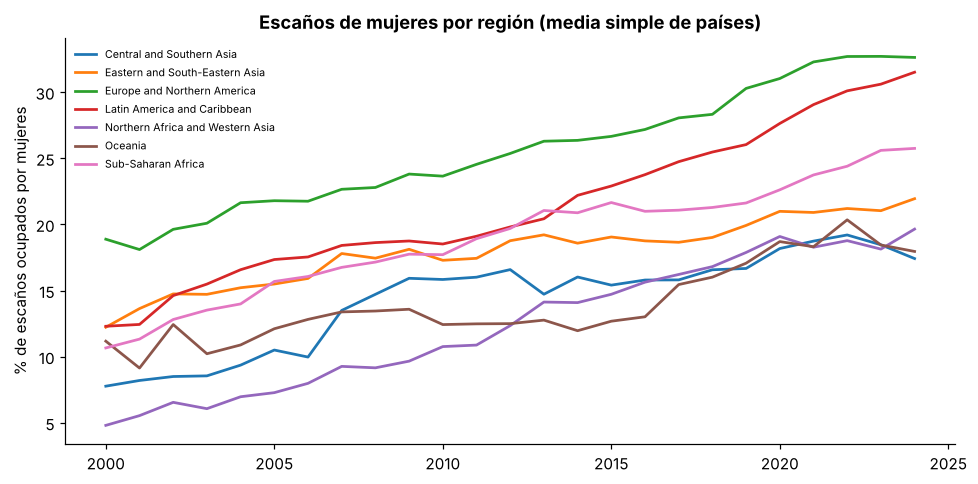

In [8]:
evol = df.groupby([REG, "anio"])[ESC].mean().unstack()
tabla = evol[[2000, 2024]].round(1).sort_values(2024)
tabla["cambio (p. p.)"] = (tabla[2024] - tabla[2000]).round(1)
print(tabla.to_string())
for a in (2000, 2024):
    print(f"Distancia entre la región más alta y la más baja en {a}: {evol[a].max() - evol[a].min():.1f} puntos")

fig, ax = plt.subplots(figsize=(9, 4.5))
for r in evol.index:
    ax.plot(evol.columns, evol.loc[r], lw=1.8, label=r)
ax.set_ylabel("% de escaños ocupados por mujeres")
ax.set_title("Escaños de mujeres por región (media simple de países)")
ax.legend(fontsize=7, loc="upper left", frameon=False)
plt.tight_layout(); plt.show()

### 6.2 Correlación: igualdad y CO₂ por habitante dentro de cada nivel de renta (pregunta 2)

*Hipótesis:* dentro de cada nivel de renta, más igualdad va con menos CO₂ por habitante. Uso la correlación de Spearman porque el CO₂ tiene una cola larga (apartado 4.2) y Spearman trabaja con rangos, así que no le afectan tanto los valores extremos.

Todos los países juntos: Spearman igualdad-CO2 por habitante = 0.01
     renta  países  igualdad-CO2 pc  renovables medias (%)
      Baja      19            -0.19                  77.13
Media baja      38            -0.33                  39.21
Media alta      49            -0.02                  12.49
      Alta      55            -0.25                   5.90


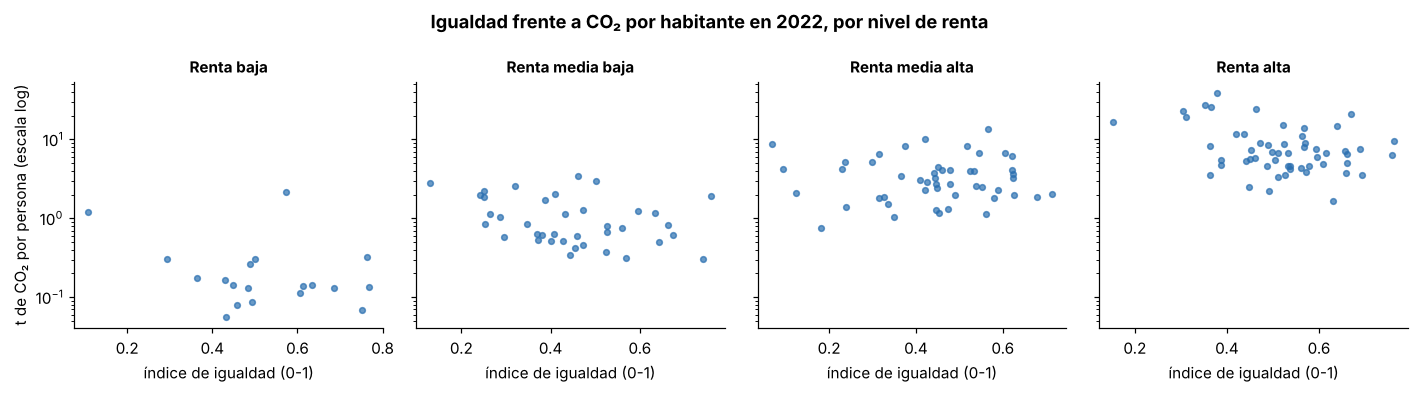

In [9]:
d22 = df[df.anio == 2022]
glob = d22[["indice_igualdad", "co2_pc"]].corr(method="spearman").iloc[0, 1]
print(f"Todos los países juntos: Spearman igualdad-CO2 por habitante = {glob:.2f}")
filas = []
for n in NIVELES:
    g = d22[d22[RENTA] == n].dropna(subset=["indice_igualdad", "co2_pc"])
    filas.append({"renta": ETIQ[n], "países": len(g),
                  "igualdad-CO2 pc": g[["indice_igualdad", "co2_pc"]].corr(method="spearman").iloc[0, 1],
                  "renovables medias (%)": d22.loc[d22[RENTA] == n, REN].mean()})
print(pd.DataFrame(filas).round(2).to_string(index=False))

fig, axs = plt.subplots(1, 4, figsize=(13, 3.6), sharey=True)
for ax, n in zip(axs, NIVELES):
    g = d22[d22[RENTA] == n]
    ax.scatter(g.indice_igualdad, g.co2_pc, s=14, color=AZUL, alpha=.7)
    ax.set_yscale("log"); ax.set_title(f"Renta {ETIQ[n].lower()}", fontsize=10)
    ax.set_xlabel("índice de igualdad (0-1)")
axs[0].set_ylabel("t de CO₂ por persona (escala log)")
plt.suptitle("Igualdad frente a CO₂ por habitante en 2022, por nivel de renta", fontweight="bold")
plt.tight_layout(); plt.show()

### 6.3 Distribución: brecha de participación laboral según renta y electricidad (pregunta 3)

*Hipótesis:* la brecha es mayor donde faltan servicios básicos. Comparo la brecha media por nivel de renta en 2022 y la relación con el acceso a electricidad.

Brecha de participación media en 2022 (p. p.):
Income Classification (World Bank Definition)
Baja          13.0
Media baja    22.0
Media alta    23.3
Alta          15.7


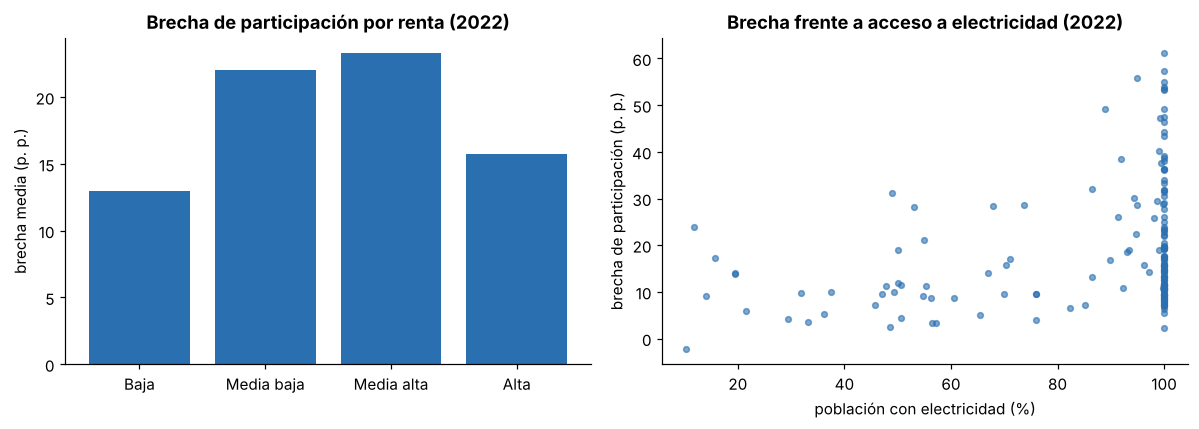

In [10]:
b = d22.groupby(RENTA)["brecha_participacion_pp"].mean().reindex(NIVELES)
print("Brecha de participación media en 2022 (p. p.):")
print(b.rename(index=ETIQ).round(1).to_string())

fig, axs = plt.subplots(1, 2, figsize=(11, 4))
axs[0].bar([ETIQ[n] for n in NIVELES], b.values, color=AZUL)
axs[0].set_ylabel("brecha media (p. p.)"); axs[0].set_title("Brecha de participación por renta (2022)")
axs[1].scatter(d22[ELEC], d22.brecha_participacion_pp, s=14, color=AZUL, alpha=.6)
axs[1].set_xlabel("población con electricidad (%)"); axs[1].set_ylabel("brecha de participación (p. p.)")
axs[1].set_title("Brecha frente a acceso a electricidad (2022)")
plt.tight_layout(); plt.show()

### 6.4 Trayectorias: igualdad según el desacoplamiento (pregunta 4) y 6.5 según el régimen (pregunta 5)

El desacoplamiento es un valor por país (apartado 4 del documento), así que tomo una fila por país, la de 2024.

In [11]:
d24 = df[df.anio == 2024]
desac = np.where(d24.desacoplamiento > 0, "positivo (crece contaminando menos)", "cero o negativo")
print(d24.groupby(desac)["indice_igualdad"].agg(["count", "mean"]).round(2).to_string())
print()
orden = ["Closed Autocracy", "Electoral Autocracy", "Electoral Democracy", "Liberal Democracy"]
print(d24.groupby("regimen")["indice_igualdad"].agg(["count", "mean"]).reindex(orden).round(2).to_string())

                                     count  mean
cero o negativo                         47  0.45
positivo (crece contaminando menos)    109  0.50

                     count  mean
regimen                         
Closed Autocracy        19  0.42
Electoral Autocracy     50  0.47
Electoral Democracy     53  0.48
Liberal Democracy       28  0.58


### 6.6 Media simple frente a media ponderada, cobertura del Gini y control del CO₂

Tres comprobaciones del diccionario y de los sesgos: cuánto cambia la media de escaños si pondero por población, cómo se reparten los huecos del Gini por nivel de renta y si `co2_pc` coincide con `co2_pc_owid`.

In [12]:
e24 = d24.dropna(subset=[ESC, POB])
print(f"Escaños de mujeres en 2024: media simple {e24[ESC].mean():.1f} %, "
      f"ponderada por población {np.average(e24[ESC], weights=e24[POB]):.1f} %")
print("Países más poblados:")
print(e24.nlargest(4, POB)[["pais", ESC]].round(1).to_string(index=False))
print()
GINI = "Gini index (World Bank estimate) - SI.POV.GINI"
print("% de registros con Gini por nivel de renta:")
print((df.groupby(RENTA)[GINI].apply(lambda s: s.notna().mean() * 100)).reindex(NIVELES).rename(index=ETIQ).round(1).to_string())
print()
dif = (df.co2_pc - df.co2_pc_owid).abs()
print(f"co2_pc frente a co2_pc_owid: {(dif < 0.05).mean() * 100:.0f} % de los registros con menos de 0,05 t de diferencia "
      f"(mediana {dif.median():.3f} t)")

Escaños de mujeres en 2024: media simple 26.6 %, ponderada por población 23.4 %
Países más poblados:
         pais  Proportion of seats held by women in national parliaments (%) - SG.GEN.PARL.ZS
        India                                                                            13.7
        China                                                                            26.5
United States                                                                            28.7
    Indonesia                                                                            21.0

% de registros con Gini por nivel de renta:
Income Classification (World Bank Definition)
Baja          18.7
Media baja    36.3
Media alta    48.6
Alta          57.7

co2_pc frente a co2_pc_owid: 85 % de los registros con menos de 0,05 t de diferencia (mediana 0.000 t)
